# Przetwarzanie języka naturalnego (NLP) - analiza sentymentu, klasyfikacja dokumentów.

# Zaimportowanie oraz zainstalowanie potrzebnych bibliotek:

In [50]:
!pip install scikit-learn nltk

In [51]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import seaborn as sns
import matplotlib.pyplot as plt
import re
import nltk
import random

# Wczytywanie danych

20 Newsgroups to zbiór około 20 000 dokumentów podzielonych na 20 grup tematycznych. Popularny zestaw do eksperymentów z technikami uczenia maszynowego.

In [52]:
newsgroups_all = fetch_20newsgroups(subset='all', shuffle=True, remove=('headers', 'footers', 'quotes'))

# Sprawdzamy jakie są kategorie oraz ile jest artkyłów:

In [53]:
print(f"Liczba artykułów: {len(newsgroups_all.data)}")
print(f"Liczba kategorii: {len(newsgroups_all.target_names)}\n")
print("Kategorie:")
print(newsgroups_all.target_names)

Liczba artykułów: 18846
Liczba kategorii: 20

Kategorie:
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


# Wyświetlamy kilka artykułów oraz ich kategorie:

In [54]:
for i in range(3):
    idx = random.randint(0, len(newsgroups_all.data) - 1)
    print(f"\n--- Artykuł {i+1} ---")
    print(f"Kategoria: {newsgroups_all.target_names[newsgroups_all.target[idx]]}")
    print(newsgroups_all.data[idx][:500], "...")


--- Artykuł 1 ---
Kategoria: rec.sport.hockey
[obnoxious name-calling deleted]

	Ok, who wants rm off of here? I say we get his net privleges revoked.
	Any seconds?
 ...

--- Artykuł 2 ---
Kategoria: alt.atheism

	Perhaps we ought not to have supported a known genocidist?
	Provided him with weapon systems, tactical support, technology,
etc.

	We made Suddam Hussein.

	What did Bush call him? Oh yes, an ally and a freind.


---  

  " I'd Cheat on Hillary Too." ...

--- Artykuł 3 ---
Kategoria: sci.crypt

How can you be sure the two visitors were really government agents?
:-)

--John ...


# Podział na dane testowe, walidacyjne i treningowe:

In [55]:
X_temp, X_test, y_temp, y_test = train_test_split(
    newsgroups_all.data, newsgroups_all.target,
    test_size=0.15, random_state=42, stratify=newsgroups_all.target)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1765, random_state=42, stratify=y_temp)

print(f"Treningowe: {len(X_train)}")
print(f"Walidacyjne: {len(X_val)}")
print(f"Testowe: {len(X_test)}")

Treningowe: 13191
Walidacyjne: 2828
Testowe: 2827


# Czyszczenia artykułów:

In [56]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

X_train_clean = [clean_text(doc) for doc in X_train]
X_val_clean = [clean_text(doc) for doc in X_val]
X_test_clean = [clean_text(doc) for doc in X_test]

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Wektoryzacja za pomocą TfidVectorizer:




In [57]:
vectorizer = TfidfVectorizer(max_features=10000)

X_train_vec = vectorizer.fit_transform(X_train_clean)
X_val_vec = vectorizer.transform(X_val_clean)
X_test_vec = vectorizer.transform(X_test_clean)

print("TF-IDF wektory:")
print(f"Train: {X_train_vec.shape}")
print(f"Val:   {X_val_vec.shape}")
print(f"Test:  {X_test_vec.shape}")

TF-IDF wektory:
Train: (13191, 10000)
Val:   (2828, 10000)
Test:  (2827, 10000)


# Trenowanie modelu:

Wybrano model Naive Bayes:
Naive Bayes to rodzina klasyfikatorów opartych na twierdzeniu Bayesa, która stosuje podejście probabilistyczne do klasyfikacji. W swojej najprostszej formie, model ten przyjmuje, że wszystkie cechy (słowa) są niezależne od siebie, co jest założeniem "naivnym" (stąd nazwa). Mimo tego założenia, Naive Bayes działa bardzo dobrze w wielu zadaniach, takich jak analiza sentymentu czy klasyfikacja tekstu.

In [58]:
model = MultinomialNB()
model.fit(X_train_vec, y_train)

y_val_pred = model.predict(X_val_vec)

# Raport klasyfikacji oraz dokładność modelu:

In [59]:
print("Raport klasyfikacji (walidacyjne):\n")
print(classification_report(y_val, y_val_pred, target_names=newsgroups_all.target_names))

Raport klasyfikacji (walidacyjne):

                          precision    recall  f1-score   support

             alt.atheism       0.74      0.42      0.53       120
           comp.graphics       0.59      0.64      0.61       146
 comp.os.ms-windows.misc       0.72      0.64      0.68       148
comp.sys.ibm.pc.hardware       0.66      0.75      0.70       147
   comp.sys.mac.hardware       0.77      0.66      0.71       145
          comp.windows.x       0.75      0.76      0.75       148
            misc.forsale       0.78      0.78      0.78       146
               rec.autos       0.76      0.71      0.73       148
         rec.motorcycles       0.79      0.75      0.77       150
      rec.sport.baseball       0.82      0.82      0.82       149
        rec.sport.hockey       0.51      0.86      0.64       150
               sci.crypt       0.75      0.77      0.76       149
         sci.electronics       0.75      0.59      0.66       148
                 sci.med       0.82    

Można zauważyć, że dla kategorii talk.religion.misc recall wynosi 0,05 - model praktycznie nie rozpoznaje tej kategorii

In [60]:
print(f"Dokładność (accuracy): {accuracy_score(y_val, y_val_pred):.4f}")

Dokładność (accuracy): 0.6977


# Macierz błędów:

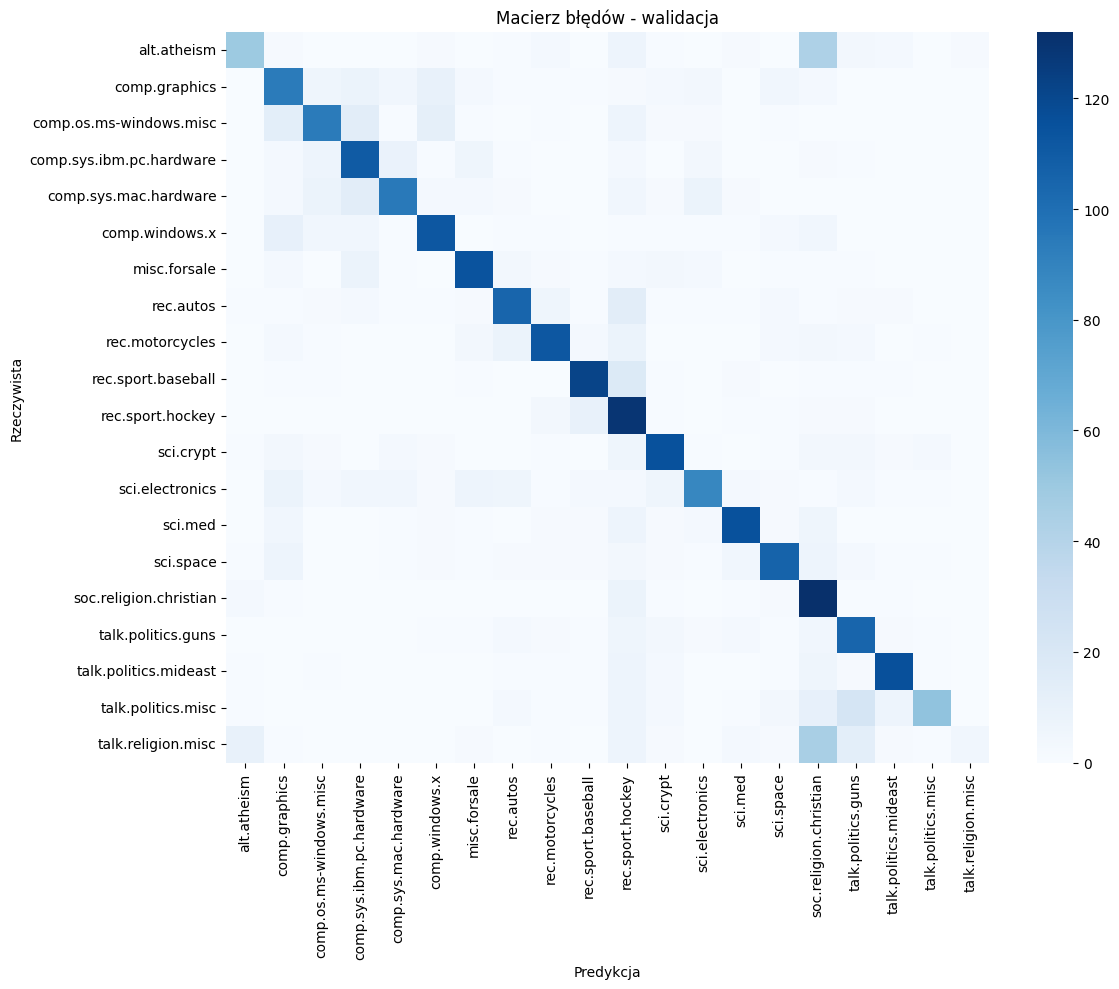

In [61]:
cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=newsgroups_all.target_names, yticklabels=newsgroups_all.target_names, annot=False)
plt.title("Macierz błędów - walidacja")
plt.xlabel("Predykcja")
plt.ylabel("Rzeczywista")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Sprawdzamy jak model radzi sobie na danych testowych:

In [62]:
y_test_pred = model.predict(X_test_vec)

print("Raport klasyfikacji (testowe):\n")
print(classification_report(y_test, y_test_pred, target_names=newsgroups_all.target_names))

Raport klasyfikacji (testowe):

                          precision    recall  f1-score   support

             alt.atheism       0.80      0.36      0.49       120
           comp.graphics       0.67      0.66      0.67       146
 comp.os.ms-windows.misc       0.68      0.61      0.65       148
comp.sys.ibm.pc.hardware       0.59      0.74      0.66       147
   comp.sys.mac.hardware       0.74      0.62      0.67       144
          comp.windows.x       0.77      0.86      0.81       148
            misc.forsale       0.81      0.66      0.73       146
               rec.autos       0.74      0.74      0.74       149
         rec.motorcycles       0.78      0.66      0.72       149
      rec.sport.baseball       0.88      0.80      0.84       149
        rec.sport.hockey       0.55      0.91      0.69       150
               sci.crypt       0.78      0.83      0.81       149
         sci.electronics       0.75      0.70      0.73       148
                 sci.med       0.83      0.

In [63]:
print(f"Dokładność (accuracy): {accuracy_score(y_test, y_test_pred):.4f}")

Dokładność (accuracy): 0.7039


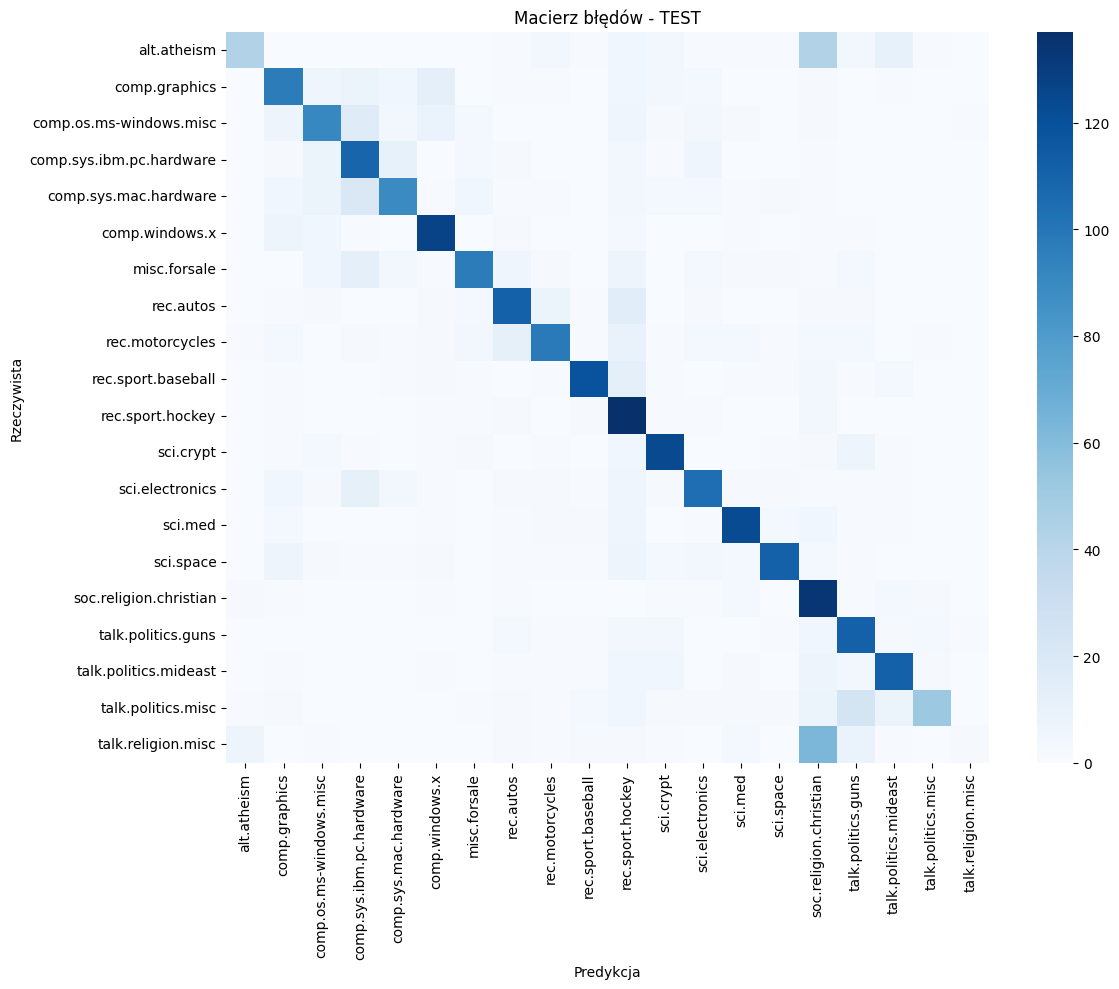

In [64]:
cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm_test, cmap="Blues", xticklabels=newsgroups_all.target_names, yticklabels=newsgroups_all.target_names, annot=False)
plt.title("Macierz błędów - TEST")
plt.xlabel("Predykcja")
plt.ylabel("Rzeczywista")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Wnioski:

- Model Naive Bayes osiągnął dokładność (accuracy) 70% na danych testowych, co oznacza, że dla 7 na 10 przypadków, model poprawnie klasyfikował artykuły do odpowiednich kategorii.
- talk.religion.misc ma bardzo niski recall (0.02), co oznacza, że model praktycznie nie klasyfikuje tego typu artykułów. Może to być spowodowane:
  *   Podobieństwem tematycznym z innymi kategoriami,
  *   Brakiem wystarczającej liczby przykładów w danych treningowych.
- Precyzja i recall są różne dla różnych klas:
  *   Niektóre klasy (np. rec.sport.baseball, sci.med) mają bardzo wysoką precyzję i recall, co oznacza, że model skutecznie identyfikuje te kategorie.
  *   Inne klasy (np. talk.religion.misc, alt.atheism) mają niski recall, co sugeruje, że model nie radzi sobie z odróżnianiem tych kategorii.









